# Meadow Distribution fleet data: exploratory analysis

Synthetic data for eight diesel vehicles, 5 to 16 October 2026.

**Main findings**

1. The raw telemetry needed cleaning: repeated rows, placeholder values, blank fuel readings, two trips with missing intervals and six events that could not be linked to a trip and vehicle.
2. VEH03 (van): idle share goes from about 13% to about 40% from 12 October. No other vehicle changes like this.
3. VEH06 (rigid truck): fuel use is above its class benchmark on every day, by 26% on average, with normal idling. Its peer VEH05 is within 2%.
4. Event rates are highest on urban routes, so they mostly reflect where vehicles operate.

## 0. What the data pack states

* Distance and fuel are interval amounts, so they can be summed. Fuel already includes idling.
* Intervals are 300 s, and idle time is part of engine-on time.
* Blank means unavailable, not zero. The export can contain retries, invalid readings and gaps.
* Use observation time, not received time, and parse the timestamp offsets.
* Benchmarks and events are illustrative, and events are not proof of unsafe driving. Cost and CO2 need labelled assumptions.

## 1. Load the data

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
DATA = '/content/'

vehicles = pd.read_csv(DATA + 'vehicles.csv')
drivers = pd.read_csv(DATA + 'drivers.csv')
trips = pd.read_csv(DATA + 'trips.csv')
samples = pd.read_csv(DATA + 'telemetry_samples.csv')
events = pd.read_csv(DATA + 'driver_events.csv')
dictionary = pd.read_csv(DATA + 'data_dictionary.csv')

for name, df in [('vehicles', vehicles), ('drivers', drivers), ('trips', trips), ('samples', samples), ('events', events)]:
    print(name, len(df), list(df.columns))

vehicles 8 ['vehicle_id', 'vehicle_class', 'fuel_type', 'depot', 'illustrative_benchmark_l_per_100km']
drivers 12 ['driver_id', 'display_name']
trips 160 ['trip_id', 'vehicle_id', 'driver_id', 'start_time_utc', 'end_time_utc', 'route_type', 'load_band', 'weather', 'planned_distance_km']
samples 2178 ['export_row_id', 'sample_id', 'trip_id', 'event_time_utc', 'received_time_utc', 'interval_seconds', 'engine_on_seconds', 'distance_km', 'fuel_used_l', 'idle_seconds', 'average_speed_kph']
events 215 ['export_row_id', 'event_id', 'trip_id', 'vehicle_id', 'driver_id', 'event_time_utc', 'event_type', 'detector_severity', 'duration_seconds', 'recorded_speed_kph', 'detector_limit_kph']


In [2]:
dictionary

,table,field,unit_or_type,definition
0,vehicles,vehicle_id,text,Join to trips.vehicle_id and driver_events.veh...
1,vehicles,vehicle_class,category,"van, rigid_truck, articulated_truck. Compare s..."
2,vehicles,fuel_type,category,All vehicles use diesel in this exercise.
3,vehicles,depot,category,Fictional depot label; no actual location.
4,vehicles,illustrative_benchmark_l_per_100km,litres/100 km,"Fictional comparison reference, not a manufact..."
5,drivers,driver_id,text,Join via trips.driver_id; driver events also c...
6,drivers,display_name,text,Anonymous fictional label only.
7,trips,trip_id,text,Unique key; joins telemetry_samples.trip_id an...
8,trips,vehicle_id,text,Vehicle assigned to the trip.
9,trips,driver_id,text,Authoritative driver assignment for this exerc...


In [3]:
vehicles

,vehicle_id,vehicle_class,fuel_type,depot,illustrative_benchmark_l_per_100km
0,VEH01,van,diesel,Depot North,10.5
1,VEH02,van,diesel,Depot South,10.5
2,VEH03,van,diesel,Depot North,10.5
3,VEH04,van,diesel,Depot South,10.5
4,VEH05,rigid_truck,diesel,Depot North,24.0
5,VEH06,rigid_truck,diesel,Depot South,24.0
6,VEH07,articulated_truck,diesel,Depot North,31.0
7,VEH08,articulated_truck,diesel,Depot South,31.0


In [4]:
trips.head()

,trip_id,vehicle_id,driver_id,start_time_utc,end_time_utc,route_type,load_band,weather,planned_distance_km
0,TRP0001,VEH01,DRV01,2026-10-05T07:00:00Z,2026-10-05T08:30:00Z,urban,heavy,dry,36.07
1,TRP0002,VEH02,DRV02,2026-10-05T07:05:00Z,2026-10-05T07:50:00Z,urban,light,dry,18.62
2,TRP0003,VEH03,DRV03,2026-10-05T07:10:00Z,2026-10-05T08:10:00Z,urban,heavy,dry,24.98
3,TRP0004,VEH04,DRV04,2026-10-05T07:15:00Z,2026-10-05T08:00:00Z,mixed,light,dry,34.85
4,TRP0005,VEH05,DRV05,2026-10-05T07:20:00Z,2026-10-05T08:35:00Z,mixed,light,dry,62.70


In [5]:
samples.head()

,export_row_id,sample_id,trip_id,event_time_utc,received_time_utc,interval_seconds,engine_on_seconds,distance_km,fuel_used_l,idle_seconds,average_speed_kph
0,TEL01232,SMP01232,TRP0093,2026-10-12T13:15:00Z,2026-10-12T13:15:20Z,300,300,4.248,0.9695,25,50.98
1,TEL02057,SMP02057,TRP0154,2026-10-16T12:15:00Z,2026-10-16T12:16:07Z,300,300,2.312,0.2488,24,27.74
2,TEL00375,SMP00375,TRP0029,2026-10-06T13:20:00Z,2026-10-06T13:21:11Z,300,300,4.143,1.0353,14,49.72
3,TEL01134,SMP01134,TRP0086,2026-10-12T08:40:00Z,2026-10-12T08:40:25Z,300,300,4.582,1.4668,10,54.98
4,TEL00401,SMP00401,TRP0031,2026-10-06T13:10:00Z,2026-10-06T13:10:43Z,300,300,4.896,1.5880,28,58.75


In [6]:
raw_times = samples['event_time_utc'].copy()

def to_utc(s):
    return pd.to_datetime(s, format='ISO8601', utc=True).dt.round('s')

trips['start_time_utc'] = to_utc(trips['start_time_utc'])
trips['end_time_utc'] = to_utc(trips['end_time_utc'])
samples['event_time_utc'] = to_utc(samples['event_time_utc'])
samples['received_time_utc'] = to_utc(samples['received_time_utc'])
events['event_time_utc'] = to_utc(events['event_time_utc'])

samples['date'] = samples.event_time_utc.dt.strftime('%Y-%m-%d')
print(sorted(samples.date.unique()))

['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09', '2026-10-12', '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16']


**Notes.** Five tables: two lookups (vehicles, drivers), trips (160), telemetry samples (2,178 raw rows) and events (215 raw rows). Samples and events join to trips on "trip_id". The data covers ten weekdays.

## 2. Data quality checks

### 2.1 Repeated rows

In [61]:
print(f"Trips duplicates:   {trips.trip_id.duplicated().sum()}")
print(f"Samples duplicates: {samples.sample_id.duplicated().sum()}")
print(f"Events duplicates:  {events.event_id.duplicated().sum()}")

# duplicates in samples
dups = samples[samples.sample_id.duplicated(keep=False)].sort_values('sample_id')
display(dups.head(6))

Trips duplicates:   0
Samples duplicates: 24
Events duplicates:  12


,export_row_id,sample_id,trip_id,event_time_utc,received_time_utc,interval_seconds,engine_on_seconds,distance_km,fuel_used_l,idle_seconds,average_speed_kph
242,TEL_DUP001,SMP01807,TRP0135,2026-10-15T08:05:00Z,2026-10-15T08:05:57Z,300,300,6.561,1.9155,6,78.73
113,TEL01807,SMP01807,TRP0135,2026-10-15T08:05:00Z,2026-10-15T08:05:57Z,300,300,6.561,1.9155,6,78.73
555,TEL_DUP002,SMP01808,TRP0135,2026-10-15T08:10:00Z,2026-10-15T08:11:01Z,300,300,5.479,1.6027,10,65.75
674,TEL01808,SMP01808,TRP0135,2026-10-15T08:10:00Z,2026-10-15T08:11:01Z,300,300,5.479,1.6027,10,65.75
347,TEL01809,SMP01809,TRP0135,2026-10-15T08:15:00Z,2026-10-15T08:16:04Z,300,300,5.973,1.7485,13,71.68
1176,TEL_DUP003,SMP01809,TRP0135,2026-10-15T08:15:00Z,2026-10-15T08:16:04Z,300,300,5.973,1.7485,13,71.68


In [62]:
s_dups = samples[samples.sample_id.duplicated(keep=False)].drop(columns='export_row_id')
print(f"Samples: {s_dups.sample_id.nunique()} IDs repeated, {len(s_dups.drop_duplicates())} distinct versions")

e_dups = events[events.event_id.duplicated(keep=False)].drop(columns='export_row_id')
print(f"Events: {e_dups.event_id.nunique()} IDs repeated, {len(e_dups.drop_duplicates())} distinct versions")

Samples: 24 IDs repeated, 24 distinct versions
Events: 12 IDs repeated, 12 distinct versions


**Notes.** The repeated rows differ only in `export_row_id`, so they are retries. Summing them would double count 24 intervals and 12 events. The first copy is kept.

### 2.2 Ranges and impossible values

In [9]:
samples[['distance_km', 'fuel_used_l', 'idle_seconds', 'engine_on_seconds', 'average_speed_kph']].describe().round(2)

,distance_km,fuel_used_l,idle_seconds,engine_on_seconds,average_speed_kph
count,2178.00,2172.00,2178.00,2178.0,2178.00
mean,3.73,0.96,29.76,300.0,45.32
std,1.66,1.95,33.58,0.0,22.75
min,-2.00,0.11,5.00,300.0,7.61
25%,2.21,0.24,12.00,300.0,26.53
50%,3.72,0.79,19.00,300.0,44.68
75%,4.91,1.52,27.00,300.0,59.50
max,7.28,50.00,210.00,300.0,350.00


In [10]:
print(samples.interval_seconds.value_counts())
print(samples.distance_km.sort_values().head(6).tolist())
print(samples.fuel_used_l.dropna().sort_values().tail(6).tolist())
print(samples.average_speed_kph.sort_values().tail(6).tolist())
print(samples.idle_seconds.sort_values().tail(6).tolist())
print('idle above engine on:', (samples.idle_seconds > samples.engine_on_seconds).sum())

interval_seconds
300    2178
Name: count, dtype: int64
[-2.0, -2.0, -2.0, -2.0, 0.634, 0.689]
[2.4339, 2.4492, 2.4548, 50.0, 50.0, 50.0]
[87.32, 87.37, 87.41, 350.0, 350.0, 350.0]
[199, 200, 204, 207, 209, 210]
idle above engine on: 0


**Notes.** A distance of -2 km (4 rows), a fuel reading of 50 L (3 rows; the next highest is about 2.5 L) and a speed of 350 kph (3 rows) are placeholders, not real readings. Idle values up to 210 s are plausible.

### 2.3 Missing values

In [11]:
print(samples.isna().sum())
missing_fuel = samples[samples.fuel_used_l.isna()].merge(trips[['trip_id', 'vehicle_id']], on='trip_id')
print(missing_fuel[['sample_id', 'trip_id', 'vehicle_id', 'distance_km']])
print(missing_fuel.vehicle_id.value_counts())

export_row_id        0
sample_id            0
trip_id              0
event_time_utc       0
received_time_utc    0
interval_seconds     0
engine_on_seconds    0
distance_km          0
fuel_used_l          6
idle_seconds         0
average_speed_kph    0
date                 0
dtype: int64
  sample_id  trip_id vehicle_id  distance_km
0  SMP00502  TRP0039      VEH07        5.643
1  SMP00877  TRP0065      VEH01        1.892
2  SMP00263  TRP0021      VEH05        3.625
3  SMP01186  TRP0090      VEH02        2.365
4  SMP00045  TRP0004      VEH04        4.331
5  SMP00136  TRP0011      VEH03        1.809
vehicle_id
VEH07    1
VEH01    1
VEH05    1
VEH02    1
VEH04    1
VEH03    1
Name: count, dtype: int64


**Notes.** Six fuel readings are blank, one on each of six different vehicles. They are not treated as zero and are left out only of calculations that need fuel.

### 2.4 Do the fields agree with each other?

In [12]:
expected_speed = samples.distance_km / (samples.interval_seconds / 3600)
mismatch = samples[(expected_speed - samples.average_speed_kph).abs() > 1]
print(len(mismatch))
mismatch[['sample_id', 'distance_km', 'average_speed_kph']].assign(expected=expected_speed.round(1))

7


,sample_id,distance_km,average_speed_kph,expected
251,SMP00080,-2.000,85.84,-24.0
266,SMP00613,-2.000,61.87,-24.0
350,SMP00911,3.334,350.00,40.0
1120,SMP00130,2.027,350.00,24.3
1323,SMP01342,-2.000,50.68,-24.0
1541,SMP00220,-2.000,26.74,-24.0
1651,SMP00461,3.385,350.00,40.6


In [13]:
chk = samples.merge(trips[['trip_id', 'start_time_utc', 'end_time_utc']], on='trip_id', how='left')
print('unknown trip:', chk.start_time_utc.isna().sum())
print('outside trip window:', ((chk.event_time_utc <= chk.start_time_utc) | (chk.event_time_utc > chk.end_time_utc)).sum())

unknown trip: 0
outside trip window: 0


**Notes.** The seven mismatches are the same rows as in 2.2. All samples fall inside their trip windows.

### 2.5 Coverage: did every trip send all its intervals?

In [14]:
u = samples.drop_duplicates('sample_id')
trips['expected'] = ((trips.end_time_utc - trips.start_time_utc).dt.total_seconds() / 300).round().astype(int)
trips['observed'] = trips.trip_id.map(u.groupby('trip_id').size()).fillna(0).astype(int)
print('expected', trips.expected.sum(), 'observed', trips.observed.sum())
trips[trips.observed < trips.expected][['trip_id', 'vehicle_id', 'expected', 'observed']]

expected 2160 observed 2154


,trip_id,vehicle_id,expected,observed
113,TRP0114,VEH02,18,15
127,TRP0128,VEH08,18,15


**Notes.** 2,154 of 2,160 expected intervals are present. TRP0114 (VEH02) and TRP0128 (VEH08) are each missing three. This is 0.3% of intervals and has little effect.

### 2.6 Timestamps and late data

In [15]:
not_z = raw_times[~raw_times.str.endswith('Z')]
print(not_z)
print(samples.loc[not_z.index, 'event_time_utc'])

delay_hours = (samples.received_time_utc - samples.event_time_utc).dt.total_seconds() / 3600
print('received over 1 hour late:', (delay_hours > 1).sum())
print('latest received:', samples.received_time_utc.max())

470    2026-10-05T08:45:00+01:00
Name: event_time_utc, dtype: object
470   2026-10-05 07:45:00+00:00
Name: event_time_utc, dtype: datetime64[ns, UTC]
received over 1 hour late: 4
latest received: 2026-10-16 13:55:46+00:00


**Notes.** One timestamp has an offset and is converted to UTC. Four samples arrived over an hour late. Daily figures use observation time so late records stay on the right day.

### 2.7 Do events link correctly?

In [16]:
ev_unique = events.drop_duplicates('event_id')
e = ev_unique.merge(trips[['trip_id', 'vehicle_id', 'driver_id']], on='trip_id', how='left', suffixes=('_event', '_trip'))
print('trip not found:', e.vehicle_id_trip.isna().sum())
print('vehicle disagrees:', (e.vehicle_id_trip.notna() & (e.vehicle_id_trip != e.vehicle_id_event)).sum())
print('blank driver:', e.driver_id_event.isna().sum())
e[e.vehicle_id_trip.isna() | (e.vehicle_id_trip != e.vehicle_id_event)][['event_id', 'trip_id', 'vehicle_id_event', 'vehicle_id_trip']]

trip not found: 4
vehicle disagrees: 2
blank driver: 6


,event_id,trip_id,vehicle_id_event,vehicle_id_trip
78,BEH00008,TRP_UNKNOWN,VEH01,NaN
80,BEH00009,TRP_UNKNOWN,VEH03,NaN
99,BEH00012,TRP0014,VEH08,VEH06
129,BEH00011,TRP0013,VEH08,VEH05
173,BEH00007,TRP_UNKNOWN,VEH07,NaN
192,BEH00010,TRP_UNKNOWN,VEH05,NaN


**Notes.** Four events refer to an unknown trip and two name a different vehicle from their trip. The trip table is the reference, but for these six events it is unclear which side is right, so they are left out of per-vehicle and per-route rates. Event drivers are not analysed because the driver field is unreliable.

## 3. Cleaning policy

1. Repeated rows: keep the first copy.
2. A distance of 0 or less is invalid.
3. Fuel that is blank, or 10 L or more in one interval, is invalid. Blanks are never set to zero.
4. Litres per 100 km uses only intervals with valid distance and fuel.
5. Idle share uses all de-duplicated intervals.
6. Nothing is filled in or estimated.
7. Events that cannot be linked consistently are left out of vehicle and route comparisons.

In [17]:
S = samples.drop_duplicates('sample_id').copy()
S['dist_ok'] = S.distance_km > 0
S['fuel_ok'] = S.fuel_used_l.notna() & (S.fuel_used_l < 10)
S['pair_ok'] = S.dist_ok & S.fuel_ok

S = S.merge(trips[['trip_id', 'vehicle_id', 'driver_id', 'route_type', 'load_band', 'weather']], on='trip_id')
S = S.merge(vehicles[['vehicle_id', 'vehicle_class', 'illustrative_benchmark_l_per_100km']], on='vehicle_id')
S = S.rename(columns={'illustrative_benchmark_l_per_100km': 'bench'})

E = events.drop_duplicates('event_id').merge(trips[['trip_id', 'vehicle_id', 'route_type']], on='trip_id', how='left', suffixes=('_event', ''))
E_ok = E[E.vehicle_id == E.vehicle_id_event]

print('samples', len(samples), '->', len(S))
print('invalid distance:', (~S.dist_ok).sum(), ' invalid fuel:', (~S.fuel_ok).sum())
print('usable for litres per 100 km:', S.pair_ok.sum())
print('events', len(events), '->', len(E), '; linked:', len(E_ok))

samples 2178 -> 2154
invalid distance: 4  invalid fuel: 9
usable for litres per 100 km: 2141
events 215 -> 203 ; linked: 197


## 4. Compare vehicles

Litres per 100 km uses intervals with valid distance and fuel. Idle share is idle seconds divided by engine-on seconds. Each vehicle is compared with the (illustrative) benchmark for its own class.

In [18]:
def idle_pct(df, key):
    g = df.groupby(key)
    return g.idle_seconds.sum() / g.engine_on_seconds.sum() * 100

def l100(df, key):
    ok = df[df.pair_ok]
    g = ok.groupby(key)
    return g.fuel_used_l.sum() / g.distance_km.sum() * 100

V = pd.DataFrame({
    'class': vehicles.set_index('vehicle_id').vehicle_class,
    'km': S[S.dist_ok].groupby('vehicle_id').distance_km.sum(),
    'L_per_100km': l100(S, 'vehicle_id'),
    'idle_pct': idle_pct(S, 'vehicle_id'),
    'benchmark': S.groupby('vehicle_id').bench.first()})
V['vs_benchmark_pct'] = (V.L_per_100km / V.benchmark - 1) * 100
V.round(1)

,class,km,L_per_100km,idle_pct,benchmark,vs_benchmark_pct
vehicle_id,,,,,,
VEH01,van,520.2,11.0,13.1,10.5,5.1
VEH02,van,536.6,10.9,13.3,10.5,4.3
VEH03,van,465.7,11.5,25.4,10.5,9.9
VEH04,van,1096.1,10.7,5.6,10.5,2.0
VEH05,rigid_truck,1073.5,24.5,5.9,24.0,1.9
VEH06,rigid_truck,1078.8,30.3,5.7,24.0,26.4
VEH07,articulated_truck,1580.6,31.6,5.8,31.0,1.8
VEH08,articulated_truck,1643.7,31.2,5.9,31.0,0.7


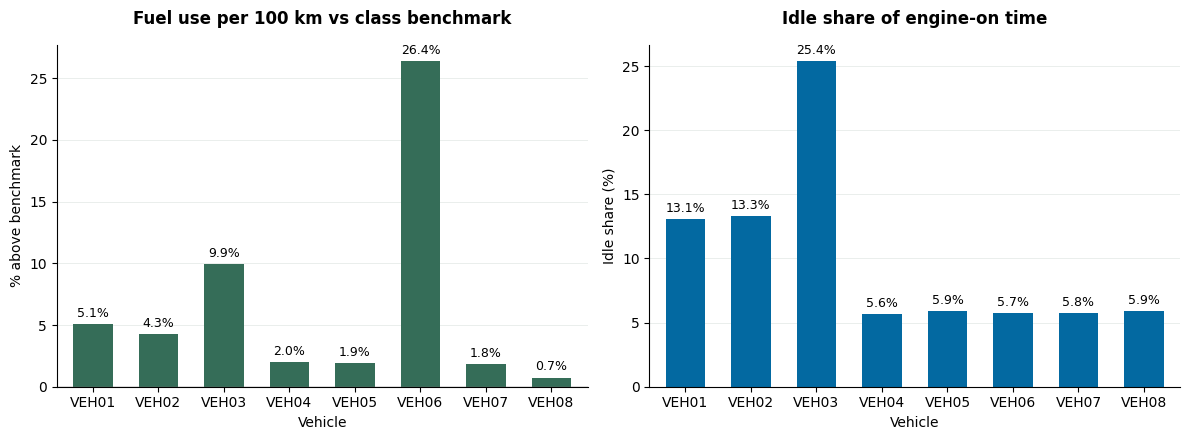

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

#  Fuel vs Benchmark
V.vs_benchmark_pct.plot.bar(ax=ax[0], color='#356d58', width=0.6)
ax[0].set_title('Fuel use per 100 km vs class benchmark', fontweight='bold', pad=15)
ax[0].set_ylabel('% above benchmark')
ax[0].set_xlabel('Vehicle')
ax[0].axhline(0, color='grey', linewidth=1)

for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.1f}%",
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom' if p.get_height() > 0 else 'top',
                   xytext=(0, 3 if p.get_height() > 0 else -12),
                   textcoords='offset points', fontsize=9)

# Idle Share
V.idle_pct.plot.bar(ax=ax[1], color='#0369a1', width=0.6)
ax[1].set_title('Idle share of engine-on time', fontweight='bold', pad=15)
ax[1].set_ylabel('Idle share (%)')
ax[1].set_xlabel('Vehicle')

for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.1f}%",
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom',
                   xytext=(0, 3),
                   textcoords='offset points', fontsize=9)

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.grid(axis='y', color='#e1e8e4', linestyle='-', linewidth=0.5, zorder=0)
    a.set_axisbelow(True)
    a.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**Notes.** VEH03 stands out among the vans on idle share (25.4% against 13.1% and 13.3% for VEH01 and VEH02) and is 9.9% above benchmark. VEH06 uses 30.3 L per 100 km, 26.4% above benchmark, while VEH05 is 1.9% above. Both articulated trucks are within 2%. VEH04's low idle share (5.6%) probably reflects its mixed routes, as VEH01 to VEH03 run urban routes. Section 5 checks whether these differences are steady or change during the period.

## 5. Investigate what stands out

Fuel use is shown as % above each vehicle's class benchmark so all vehicles fit on one axis.

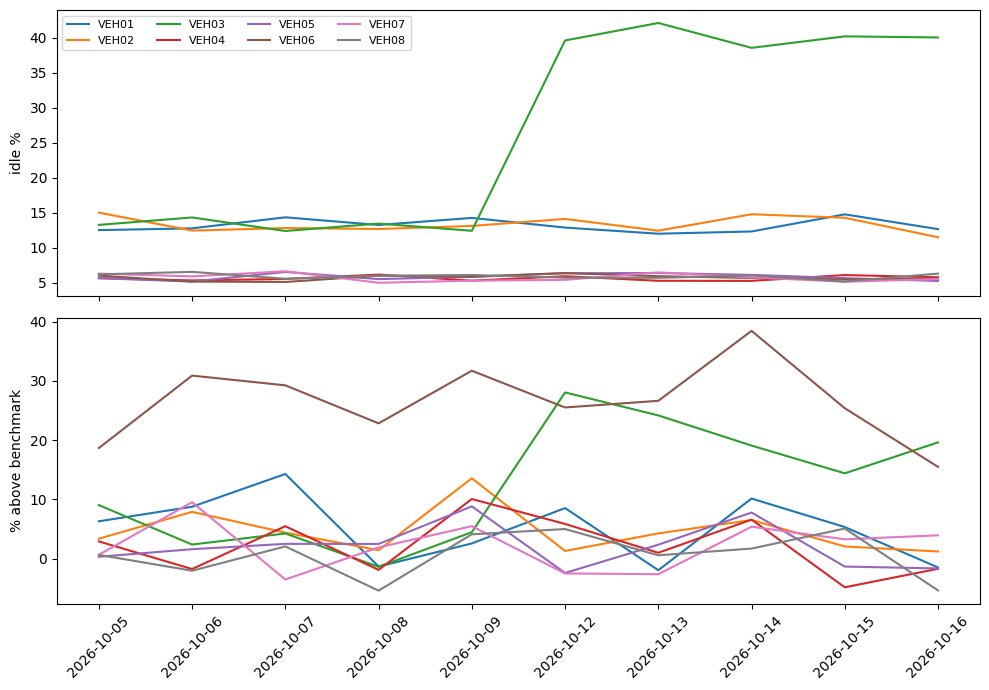

In [53]:
days = sorted(S.date.unique())

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for v in sorted(S.vehicle_id.unique()):
    g = S[S.vehicle_id == v]
    ax[0].plot(days, idle_pct(g, 'date').reindex(days), label=v)
    bench = g.bench.iloc[0]
    ax[1].plot(days, (l100(g, 'date').reindex(days) / bench - 1) * 100, label=v)
ax[0].set_ylabel('idle %')
ax[1].set_ylabel('% above benchmark')
ax[0].legend(ncol=4, fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
v6_daily = (l100(S[S.vehicle_id == 'VEH06'], 'date') / S[S.vehicle_id == 'VEH06'].bench.iloc[0] - 1) * 100

df_v6 = v6_daily.round(1).to_frame(name='% above benchmark')
display(df_v6)

# Print the mean
mean_val = round(V.loc['VEH06', 'vs_benchmark_pct'], 1)
print(f"Mean over the period: {mean_val}%")

,% above benchmark
date,
2026-10-05,18.7
2026-10-06,30.9
2026-10-07,29.2
2026-10-08,22.8
2026-10-09,31.7
2026-10-12,25.5
2026-10-13,26.6
2026-10-14,38.4
2026-10-15,25.4


Mean over the period: 26.4%


**Notes.** VEH06 is above benchmark on every day, by 26% on average, and the daily gap varies from about 16% to 38%. VEH03 is the only vehicle with a step change: idle share is near 13% up to 9 October and about 40% from 12 October, and its fuel use per 100 km rises too. Week 1 is 5 to 9 October and week 2 is 12 to 16 October.

In [22]:
S['week'] = np.where(S.date < '2026-10-10', 'week 1', 'week 2')

def summary(df, key):
    return pd.DataFrame({'trips': df.groupby(key).trip_id.nunique(),
                         'idle_pct': idle_pct(df, key),
                         'L_per_100km': l100(df, key)}).round(1)

def extra_fuel(target, peers, df):
    ok = df[df.pair_ok]
    t = ok[ok.vehicle_id == target]
    p = ok[ok.vehicle_id.isin(peers)]
    rate = p.groupby('load_band').fuel_used_l.sum() / p.groupby('load_band').distance_km.sum()
    expected = (rate * t.groupby('load_band').distance_km.sum()).sum()
    return t.fuel_used_l.sum(), expected

In [23]:
weekly = pd.DataFrame({'idle_pct': idle_pct(S, ['vehicle_id', 'week']),
                       'L_per_100km': l100(S, ['vehicle_id', 'week'])}).round(1).unstack()
weekly

idle_pct        L_per_100km       
week         week 1 week 2      week 1 week 2
vehicle_id                                   
VEH01          13.3   12.9        11.1   11.0
VEH02          13.2   13.4        11.1   10.8
VEH03          13.2   40.0        10.9   12.7
VEH04           5.6    5.7        10.8   10.6
VEH05           5.8    5.9        24.7   24.2
VEH06           5.6    5.8        30.4   30.3
VEH07           5.8    5.7        31.7   31.4
VEH08           6.1    5.8        31.0   31.4

**Notes.** The table compares week 1 with week 2 for all eight vehicles. VEH03's idle share is the only one that moves by a large amount.

### 5.1 VEH03: idle share

In [63]:
print("--- By Load Band ---")
print(summary(v3, 'load_band'))

print("\n--- By Weather ---")
print(summary(v3, 'weather'))

# Check Driver and Week TOGETHER (to avoid the pooling trap)
print("\n--- By Driver & Week ---")
print(summary(v3, ['driver_id', 'week']))

--- By Load Band ---
           trips  idle_pct  L_per_100km
load_band                              
heavy          4      32.7         13.0
light          9      24.4         11.1
medium         7      23.2         11.6

--- By Weather ---
         trips  idle_pct  L_per_100km
weather                              
dry         14      27.4         11.7
wet          6      21.3         11.2

--- By Driver & Week ---
                  trips  idle_pct  L_per_100km
driver_id week                                
DRV01     week 2      1      42.4         14.0
DRV02     week 2      1      37.9         12.9
DRV03     week 1      1      11.7         11.9
          week 2      1      41.8         12.1
DRV04     week 1      1      13.4         10.7
          week 2      1      38.9         12.5
DRV05     week 1      1      13.2         11.0
DRV06     week 1      1      14.7         10.4
DRV07     week 1      2      13.6         11.2
DRV08     week 1      1      15.2         10.8
          week 2 

In [26]:
trip_view = summary(v3, 'trip_id').join(v3.groupby('trip_id')[['date', 'driver_id']].first())
trip_view.sort_values('date')

,trips,idle_pct,L_per_100km,date,driver_id
trip_id,,,,,
TRP0003,1,11.7,11.9,2026-10-05,DRV03
TRP0011,1,14.6,11.1,2026-10-05,DRV07
TRP0019,1,13.4,10.7,2026-10-06,DRV04
TRP0027,1,15.2,10.8,2026-10-06,DRV08
TRP0035,1,13.2,11.0,2026-10-07,DRV05
TRP0043,1,11.9,10.9,2026-10-07,DRV09
TRP0051,1,14.7,10.4,2026-10-08,DRV06
TRP0059,1,12.8,10.3,2026-10-08,DRV10
TRP0075,1,12.4,10.6,2026-10-09,DRV11


In [64]:
w2 = v3[v3.week == 'week 2']
print('trips in week 2:', w2.trip_id.nunique(), ' different drivers:', w2.driver_id.nunique())

# drivers who drove VEH03 in both weeks
both = pd.DataFrame({'idle_pct': idle_pct(v3, ['driver_id', 'week'])}).unstack().round(1)
both.dropna()

trips in week 2: 10  different drivers: 9


idle_pct       
week        week 1 week 2
driver_id                
DRV03         11.7   41.8
DRV04         13.4   38.9
DRV08         15.2   41.3
DRV09         11.9   41.7
DRV10         12.8   39.1
DRV11         12.4   39.4

In [28]:
tp = trips[trips.vehicle_id == 'VEH03'].copy()
tp['week'] = np.where(tp.start_time_utc.dt.strftime('%Y-%m-%d') < '2026-10-10', 'week 1', 'week 2')
tp['minutes'] = (tp.end_time_utc - tp.start_time_utc).dt.total_seconds() / 60
tp.groupby('week')[['planned_distance_km', 'minutes']].mean().round(1)

,planned_distance_km,minutes
week,,
week 1,30.2,72.0
week 2,17.1,60.0


In [29]:
week2 = S[S.week == 'week 2']
actual, expected = extra_fuel('VEH03', ['VEH01', 'VEH02'], week2)
print('VEH03 week 2 actual:', round(actual, 1), 'L, expected at peer rates:', round(expected, 1), 'L')
print('extra:', round(actual - expected, 1), 'L')

VEH03 week 2 actual: 21.7 L, expected at peer rates: 18.9 L
extra: 2.8 L


**Notes.**
*   **The Change:** VEH03’s idle share jumped from **13.2%** to **40.0%** in Week 2, pushing fuel use up from 10.9 to 12.7 L/100km. Its peers (VEH01, VEH02) stayed flat at 13%.
*   **The Proof (Not a Driver):** 9 different drivers covered Week 2. The 6 drivers who drove in *both* weeks had ~13% idling in Week 1 and ~40% in Week 2. The change follows the vehicle, not the person.
*   **The Cause (Operational):** The van's jobs got shorter (avg 30km down to 17km) but took almost as long (72 mins down to 60 mins). This explains the extra idling.
*   **The Impact:** It wasted an extra **2.8 litres** of fuel in Week 2 against peer rates.
*   **Action:** Ask the customer what operationally changed on October 12th. The data cannot tell us why the van was sitting still.

### 5.2 VEH06: fuel use above benchmark

In [30]:
v6 = S[S.vehicle_id == 'VEH06']
print('VEH06'); print(summary(v6, 'week'))
print('VEH05'); print(summary(S[S.vehicle_id == 'VEH05'], 'week'))

VEH06
        trips  idle_pct  L_per_100km
week                                
week 1     10       5.6         30.4
week 2     10       5.8         30.3
VEH05
        trips  idle_pct  L_per_100km
week                                
week 1     10       5.8         24.7
week 2     10       5.9         24.2


In [31]:
for col in ['driver_id', 'load_band', 'weather', 'route_type']:
    print(summary(v6, col))
    print()

           trips  idle_pct  L_per_100km
driver_id                              
DRV01          2       5.9         31.5
DRV02          2       5.8         29.0
DRV03          2       5.8         27.7
DRV04          1       5.6         32.1
DRV05          1       5.7         33.2
DRV06          2       5.5         31.2
DRV07          2       5.2         28.0
DRV08          1       5.4         32.1
DRV09          1       6.1         29.5
DRV10          2       5.9         30.0
DRV11          2       6.2         32.7
DRV12          2       5.6         29.5

           trips  idle_pct  L_per_100km
load_band                              
heavy          8       5.7         32.7
light          6       5.6         27.8
medium         6       5.8         29.6

         trips  idle_pct  L_per_100km
weather                              
dry         14       5.8         29.6
wet          6       5.6         32.2

            trips  idle_pct  L_per_100km
route_type                              
mix

In [32]:
rigid = S[S.vehicle_id.isin(['VEH05', 'VEH06'])]
print(summary(rigid.assign(group=rigid.vehicle_id + ' ' + rigid.load_band), 'group'))
actual, expected = extra_fuel('VEH06', ['VEH05'], S)
print('VEH06 actual:', round(actual), 'L, expected at VEH05 rates:', round(expected), 'L')
print('extra:', round(actual - expected), 'L')

              trips  idle_pct  L_per_100km
group                                     
VEH05 heavy       6       6.1         26.7
VEH05 light       9       5.9         22.9
VEH05 medium      5       5.7         24.5
VEH06 heavy       8       5.7         32.7
VEH06 light       6       5.6         27.8
VEH06 medium      6       5.8         29.6
VEH06 actual: 326 L, expected at VEH05 rates: 268 L
extra: 58 L


**Notes.** VEH06 uses about 30 L/100km consistently, compared to 24 for its peer VEH05. Idling is normal (5.7%), so that's not the issue. The gap is there in every load band (heavy, medium, light) and they run the exact same mixed routes, so cargo weight doesn't explain it either.

Over the two weeks, this inefficiency wasted 58 litres of fuel compared to VEH05. It's likely a mechanical issue—like tyre pressure or engine tuning—but the data can't confirm the exact cause without maintenance records. A mechanical check is the next step.

### 5.3 Cost and CO2 of the extra fuel

No price or emission inputs are supplied, so the price and CO2 factor below are placeholders. Replace them with the customer's price and the current UK government diesel conversion factor.

In [33]:
price_per_l = 1.50      # placeholder GBP per litre
co2_per_l = 2.68        # placeholder kg CO2 per litre of diesel; check against current UK government conversion factors

a3, x3 = extra_fuel('VEH03', ['VEH01', 'VEH02'], week2)
a6, x6 = extra_fuel('VEH06', ['VEH05'], S)
extra = pd.Series({'VEH03 (week 2)': a3 - x3, 'VEH06 (both weeks)': a6 - x6})
pd.DataFrame({'extra_litres': extra, 'cost_GBP': extra * price_per_l, 'kg_CO2': extra * co2_per_l}).round(1)

,extra_litres,cost_GBP,kg_CO2
VEH03 (week 2),2.8,4.1,7.4
VEH06 (both weeks),58.3,87.4,156.2


**Notes.** At the placeholder price and emission factor, VEH03's extra fuel is small (about £4) and VEH06's is larger (about £87 and 156 kg CO2). Figures are for the measured days only.

## 6. Driving events

Events are signals, not proof of unsafe driving. Rates are per 100 km, and only events linked consistently to a trip and vehicle are included.

In [34]:
km = S[S.dist_ok].groupby('vehicle_id').distance_km.sum()
ev = E_ok.groupby(['vehicle_id', 'event_type']).size().unstack(fill_value=0)
ev['total'] = ev.sum(axis=1)
ev['per_100km'] = (ev.total / km * 100).round(1)
ev

event_type,harsh_acceleration,harsh_braking,speeding_signal,total,per_100km
vehicle_id,,,,,
VEH01,6,12,11,29,5.6
VEH02,5,15,11,31,5.8
VEH03,5,8,6,19,4.1
VEH04,7,14,10,31,2.8
VEH05,6,9,9,24,2.2
VEH06,5,7,9,21,1.9
VEH07,7,5,5,17,1.1
VEH08,6,11,8,25,1.5


In [35]:
by_route = pd.DataFrame({'km': S[S.dist_ok].groupby('route_type').distance_km.sum(),
                         'events': E_ok.groupby('route_type').size()})
by_route['per_100km'] = (by_route.events / by_route.km * 100).round(1)
by_route

,km,events,per_100km
route_type,,,
mixed,3248.388,76,2.3
motorway,3224.310,42,1.3
urban,1522.428,79,5.2


**Notes.** Urban routes generate 5.2 events per 100 km, compared to 2.3 on mixed routes and 1.3 on motorways.

Because each vehicle in this dataset only drives one route type (VEH01–03 are urban, VEH04–06 are mixed, VEH07–08 are motorway), vehicle and route are perfectly confounded. I can't separate the two. The rates for the urban vans are fairly close to each other (4.1 to 5.8), which suggests the higher numbers are driven by the dense urban environment, not the individual drivers. As a result, I've treated these figures as context for where the vehicles operate, not as a driver scorecard.

In [37]:
from scipy import stats

v3_daily = (S[S.vehicle_id=='VEH03']
            .groupby('date')
            .agg(idle=('idle_seconds','sum'), eng=('engine_on_seconds','sum')))
v3_daily['idle_pct'] = 100 * v3_daily.idle / v3_daily.eng

w1 = v3_daily[v3_daily.index <  '2026-10-10'].idle_pct.values
w2 = v3_daily[v3_daily.index >= '2026-10-10'].idle_pct.values

print("VEH03 daily idle share")
print(f"  week 1: n={len(w1)}, mean={w1.mean():.2f}%, sd={w1.std(ddof=1):.2f}, "
      f"range={w1.min():.1f}–{w1.max():.1f}")
print(f"  week 2: n={len(w2)}, mean={w2.mean():.2f}%, sd={w2.std(ddof=1):.2f}, "
      f"range={w2.min():.1f}–{w2.max():.1f}")

t, p = stats.ttest_ind(w1, w2, equal_var=False)           # Welch's t-test
u, p_mw = stats.mannwhitneyu(w1, w2, alternative='two-sided')  # non-parametric check
sp = np.sqrt(((len(w1)-1)*w1.var(ddof=1) + (len(w2)-1)*w2.var(ddof=1))
              / (len(w1)+len(w2)-2))
d = (w2.mean() - w1.mean()) / sp

print(f"\n  Welch t-test:      t={t:.1f}, p={p:.2e}")
print(f"  Mann-Whitney U:    U={u:.0f}, p={p_mw:.2e}")
print(f"  Cohen's d (effect size): {d:.1f}")

VEH03 daily idle share
  week 1: n=5, mean=13.18%, sd=0.80, range=12.4–14.3
  week 2: n=5, mean=40.09%, sd=1.29, range=38.5–42.1

  Welch t-test:      t=-39.6, p=3.41e-09
  Mann-Whitney U:    U=0, p=7.94e-03
  Cohen's d (effect size): 25.0


In [40]:
def daily_l100(df):
    ok = df[df.pair_ok]
    res = ok.groupby('date').agg({'fuel_used_l': 'sum', 'distance_km': 'sum'})
    return 100 * res.fuel_used_l / res.distance_km

v6 = daily_l100(S[S.vehicle_id=='VEH06'])
v5 = daily_l100(S[S.vehicle_id=='VEH05'])
bench = S[S.vehicle_id=='VEH06'].bench.iloc[0]

print("Daily L/100km")
print(f"  VEH06: n={len(v6)}, mean={v6.mean():.2f}, sd={v6.std(ddof=1):.2f}, "
      f"range={v6.min():.1f}–{v6.max():.1f}")
print(f"  VEH05: n={len(v5)}, mean={v5.mean():.2f}, sd={v5.std(ddof=1):.2f}, "
      f"range={v5.min():.1f}–{v5.max():.1f}")
print(f"  benchmark: {bench}")

# VEH06 vs benchmark (is VEH06 above 24?)
t1, p1 = stats.ttest_1samp(v6, bench)
# VEH06 vs peer VEH05 (is VEH06 above its peer?)
t2, p2 = stats.ttest_ind(v6, v5, equal_var=False)
u2, p2_mw = stats.mannwhitneyu(v6, v5, alternative='two-sided')
sp2 = np.sqrt(((len(v6)-1)*v6.var(ddof=1) + (len(v5)-1)*v5.var(ddof=1))
               / (len(v6)+len(v5)-2))
d2 = (v6.mean() - v5.mean()) / sp2

print(f"\n  VEH06 vs benchmark {bench}:  t={t1:.1f}, p={p1:.2e}")
print(f"  VEH06 vs VEH05 peer:         t={t2:.1f}, p={p2:.2e}, "
      f"Mann-Whitney p={p2_mw:.2e}")
print(f"  Cohen's d (VEH06 vs VEH05): {d2:.1f}")

Daily L/100km
  VEH06: n=10, mean=30.36, sd=1.59, range=27.7–33.2
  VEH05: n=10, mean=24.49, sd=0.90, range=23.4–26.1
  benchmark: 24.0

  VEH06 vs benchmark 24.0:  t=12.6, p=4.95e-07
  VEH06 vs VEH05 peer:         t=10.1, p=6.62e-08, Mann-Whitney p=1.83e-04
  Cohen's d (VEH06 vs VEH05): 4.5


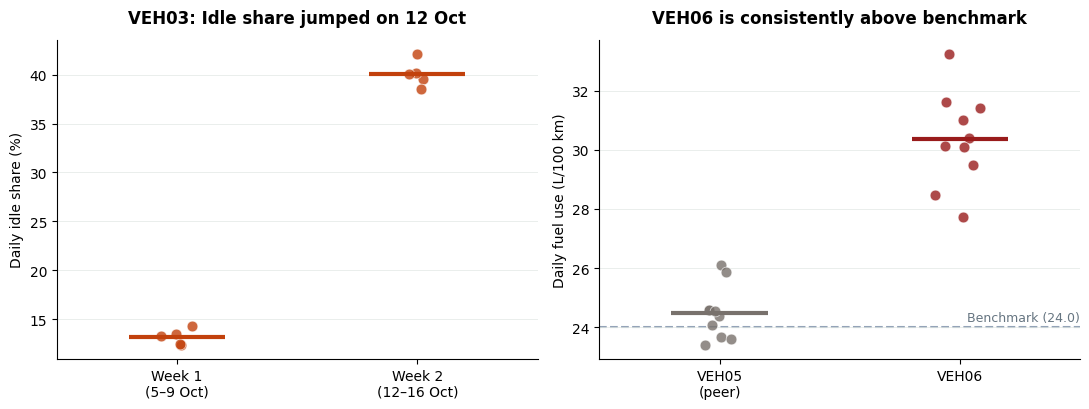

In [41]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

# ---- VEH03 (left) ----
x1 = np.random.normal(1, 0.04, len(w1))  # tiny jitter so dots don't overlap
x2 = np.random.normal(2, 0.04, len(w2))

ax[0].scatter(x1, w1, color='#c2410c', s=60, alpha=0.8, edgecolor='white', linewidth=0.5)
ax[0].scatter(x2, w2, color='#c2410c', s=60, alpha=0.8, edgecolor='white', linewidth=0.5)

# Mean lines
ax[0].hlines(w1.mean(), 0.8, 1.2, color='#c2410c', linewidth=3)
ax[0].hlines(w2.mean(), 1.8, 2.2, color='#c2410c', linewidth=3)

ax[0].set_xticks([1, 2])
ax[0].set_xticklabels(['Week 1\n(5–9 Oct)', 'Week 2\n(12–16 Oct)'])
ax[0].set_ylabel('Daily idle share (%)')
ax[0].set_title('VEH03: Idle share jumped on 12 Oct', fontweight='bold', pad=12)
ax[0].set_xlim(0.5, 2.5)

# ---- VEH06 (right) ----
x5 = np.random.normal(1, 0.04, len(v5))
x6 = np.random.normal(2, 0.04, len(v6))

ax[1].scatter(x5, v5, color='#78716c', s=60, alpha=0.8, edgecolor='white', linewidth=0.5)
ax[1].scatter(x6, v6, color='#991b1b', s=60, alpha=0.8, edgecolor='white', linewidth=0.5)

# Mean lines
ax[1].hlines(v5.mean(), 0.8, 1.2, color='#78716c', linewidth=3)
ax[1].hlines(v6.mean(), 1.8, 2.2, color='#991b1b', linewidth=3)

# Benchmark line
ax[1].axhline(bench, ls='--', color='#94a3b8', linewidth=1.5, zorder=0)
ax[1].text(2.5, bench + 0.2, f'Benchmark ({bench})', color='#667581', fontsize=9, ha='right')

ax[1].set_xticks([1, 2])
ax[1].set_xticklabels(['VEH05\n(peer)', 'VEH06'])
ax[1].set_ylabel('Daily fuel use (L/100 km)')
ax[1].set_title('VEH06 is consistently above benchmark', fontweight='bold', pad=12)
ax[1].set_xlim(0.5, 2.5)

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.grid(axis='y', color='#e1e8e4', linestyle='-', linewidth=0.5, zorder=0)
    a.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 7. Limits and next steps

**Limits.** No GPS, only ten weekdays, illustrative benchmarks and assumed cost and CO2 inputs. Causes cannot be established from these fields.

**Next steps.**

* Add a daily idle share alert per vehicle (VEH03 would have triggered on 12 October).
* Use the customer's own price and emission figures.

